## Libraries

In [55]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

from sklearn.ensemble import RandomForestRegressor

from scipy.stats import randint, uniform
from sklearn.model_selection import ParameterSampler
from sklearn.model_selection import ParameterGrid

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Dataset

In [3]:
seasons = pd.read_csv("processed_data/feature_engineering_seasons.csv")
clusters = pd.read_csv("processed_data/municipalities_clusters.csv")
df = seasons.merge(clusters, left_on="municipality", right_on="name", how="left")
df.drop(columns=["name", "lat", "lon"], inplace=True)

In [4]:
date_cols = [
    "season_start",
    "season_end",
    "returns_end"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col])

df["season_duration"] = pd.to_timedelta(
    df["season_duration"]
).dt.days

df = df.sort_values(["municipality", "year"])

In [5]:
df["season_start_doy"] = (
    df["season_start"].dt.dayofyear
)

df["season_end_doy"] = (
    df["season_end"].dt.dayofyear
)

df["returns_end_doy"] = (
    df["returns_end"].dt.dayofyear
)

df["has_returns"] = (
    df["returns_num"] > 0
).astype(int)

Due to the complexity of the returns, their presence/absence and parameters cannot be predicted

# Model A: Historical features

* Only on season features
* temporal data validation
    * using 2020-2022 as training and 2023 as test
    * then 2020-2023 vs 2024 etc
* models = 
    * Lag1 (next year is predicted based on the last observation, i.e. last year)
    * Expanding Mean (next year based on the mean of previous years)
* backtesting (simulation of predictions with data I already have)
* Calculated MAE (mean average error) e RMSE (mean squared error) for each prediction model

The key concept behind both models is the stationarity of the behaviours. Lag1 is more prone to annual variations, while Expanding Mean is more robust but slower to adapt in changing contexts.

In [6]:
history_cols = [
    "season_start_doy",
    "season_end_doy",
    "season_duration",
    "season_cum_score"
]

# Feature lag 1
for col in history_cols:
    df[f"{col}_lag1"] = (
        df.groupby("municipality")[col]
        .shift(1)
    )

# Expanding historical means, excluding current year
for col in history_cols:
    df[f"{col}_mean_past"] = (
        df.groupby("municipality")[col]
        .transform(
            lambda x: x.shift(1).expanding().mean()
        )
    )

df.head(10)

,municipality,year,season_start,season_end,season_duration,season_cum_score,returns_duration,returns_end,returns_num,returns_max_duration,...,returns_end_doy,has_returns,season_start_doy_lag1,season_end_doy_lag1,season_duration_lag1,season_cum_score_lag1,season_start_doy_mean_past,season_end_doy_mean_past,season_duration_mean_past,season_cum_score_mean_past
0,Albaredo per San Marco,2020,2020-04-25,2020-11-28,217,561.506378,0,NaT,0,0,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albaredo per San Marco,2021,2021-05-14,2021-10-31,170,523.871822,0,NaT,0,0,...,NaN,0,116.0,333.0,217.0,561.506378,116.000000,333.00,217.000000,561.506378
2,Albaredo per San Marco,2022,2022-04-10,2022-11-19,223,699.567337,0,NaT,0,0,...,NaN,0,134.0,304.0,170.0,523.871822,125.000000,318.50,193.500000,542.689100
3,Albaredo per San Marco,2023,2023-03-23,2023-10-30,221,707.894516,2,2023-11-24,1,2,...,328.0,1,100.0,323.0,223.0,699.567337,116.666667,320.00,203.333333,594.981846
4,Albaredo per San Marco,2024,2024-04-30,2024-11-19,203,699.268043,0,NaT,0,0,...,NaN,0,82.0,303.0,221.0,707.894516,108.000000,315.75,207.750000,623.210013
5,Albaredo per San Marco,2025,2025-04-09,2025-12-23,258,648.305856,0,NaT,0,0,...,NaN,0,121.0,324.0,203.0,699.268043,110.600000,317.40,206.800000,638.421619
6,Albosaggia,2020,2020-05-09,2020-11-30,205,529.084012,0,NaT,0,0,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Albosaggia,2021,2021-05-26,2021-11-01,159,541.662552,0,NaT,0,0,...,NaN,0,130.0,335.0,205.0,529.084012,130.000000,335.00,205.000000,529.084012
8,Albosaggia,2022,2022-04-28,2022-11-13,199,585.414811,0,NaT,0,0,...,NaN,0,146.0,305.0,159.0,541.662552,138.000000,320.00,182.000000,535.373282
9,Albosaggia,2023,2023-04-25,2023-10-30,188,651.746554,0,NaT,0,0,...,NaN,0,118.0,317.0,199.0,585.414811,131.333333,319.00,187.666667,552.053792


In [7]:
targets = [
    "season_start_doy",
    "season_end_doy",
    "season_duration",
    "season_cum_score"
]

# Backtesting years
test_years = [2023, 2024, 2025]

results = []

for test_year in test_years:

    train = df[df["year"] < test_year].copy()

    test = df[df["year"] == test_year].copy()

    for _, row in test.iterrows():

        municipality = row["municipality"]

        history = train[
            train["municipality"] == municipality
        ].sort_values("year")

        for target in targets:

            actual = row[target]

            # Baseline 1: last value
            pred_last = history[target].iloc[-1]

            # Baseline 2: historical mean
            pred_mean = history[target].mean()

            results.append({
                "year": test_year,
                "municipality": municipality,
                "target": target,
                "actual": actual,
                "pred_last": pred_last,
                "pred_mean": pred_mean
            })

baseline_results = pd.DataFrame(results)

baseline_results.head()

,year,municipality,target,actual,pred_last,pred_mean
0,2023,Albaredo per San Marco,season_start_doy,82.000000,100.000000,116.666667
1,2023,Albaredo per San Marco,season_end_doy,303.000000,323.000000,320.000000
2,2023,Albaredo per San Marco,season_duration,221.000000,223.000000,203.333333
3,2023,Albaredo per San Marco,season_cum_score,707.894516,699.567337,594.981846
4,2023,Albosaggia,season_start_doy,115.000000,118.000000,131.333333


In [8]:
metrics = []

for target in targets:

    subset = baseline_results[
        baseline_results["target"] == target
    ]

    for model in ["pred_last", "pred_mean"]:

        mae = mean_absolute_error(
            subset["actual"],
            subset[model]
        )

        rmse = np.sqrt(
            mean_squared_error(
                subset["actual"],
                subset[model]
            )
        )

        metrics.append({
            "target": target,
            "model": model,
            "MAE": mae,
            "RMSE": rmse
        })

baseline_metrics = pd.DataFrame(metrics)

display(
    baseline_metrics.sort_values(["target", "MAE"])
)

,target,model,MAE,RMSE
6,season_cum_score,pred_last,61.274242,72.729563
7,season_cum_score,pred_mean,68.278189,83.470206
5,season_duration,pred_mean,17.939683,24.498380
4,season_duration,pred_last,19.679654,26.415265
3,season_end_doy,pred_mean,16.196970,19.747822
2,season_end_doy,pred_last,16.683983,19.976393
1,season_start_doy,pred_mean,15.620635,16.624249
0,season_start_doy,pred_last,19.714286,22.656478


Expanding Mean is better in all targets, except from season_cum_score

# Model B: Ridge regression (including geographical features)

* Variant of linear regression
* Target = predict a variable using features
    * target = season parameters (start, end, duration)
    * features = lag 1, expanding mean, geographical (alt, lat & lon)


Machine Learning model, with L2 regularization: minimizes the sum of MSE (Mean Square Error) and a sum of squared coefficients, multiplied by a penalization parameter $\lambda$.

This means that the model seeks for a compromise between accurate predictions and large coefficients, reducing risks of overfitting. It is useful when there are many features and some features are correlated


Equation:

$$
\hat{y}_i = \beta_0 + \sum_{j=1}^{p}\beta_j x_{ij}
$$

Where:

- $\hat{y}_i$: predicted value.
- $\beta_0$: intercept.
- $\beta_j$: coefficient of feature $j$.
- $x_{ij}$: value of feature $j$ for the observation $i$.
- $p$: number of features.

Coefficient contribute to the prediction:
- Positive coefficient = positive relation with the target.
- Near-zero coefficient = little contribution.

Cost function in Ridge Regression

$$
J(\beta) =
\underbrace{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}_{MSE}
+
\underbrace{\lambda\sum_{j=1}^{p}\beta_j^2}_{L2\ Penalty}
$$

Where:

- $n$: number of observations.
- $y_i$: actual value.
- $\hat{y}_i$: predicted value.
- $\lambda$: regularization strength.
- $\sum_{j=1}^{p}\beta_j^2$: squared sum of coefficient, excluding intercept.

In [9]:
geo_data = pd.read_csv("processed_data/municipalities.csv")

In [10]:
df = df.merge(geo_data, left_on="municipality", right_on="name", how="left")

In [11]:
df.drop(columns=["name", "loc_name", "place"], inplace=True)

In [12]:
history_features = [
    "season_start_doy_lag1",
    "season_end_doy_lag1",
    "season_duration_lag1",
    "season_cum_score_lag1",
    "season_start_doy_mean_past",
    "season_end_doy_mean_past",
    "season_duration_mean_past",
    "season_cum_score_mean_past"
]

geo_features = ["ele", "lat", "lon"]

numeric_features = history_features + geo_features

The penalization parameter $\lambda$ is called alpha in the code.

Different values of Alpha should be tested:
* $alpha=0$ means to penalization, so a standard linear regression
* $alpha=0.01$ very weak
* $alpha=0.1$ weak
* $alpha=1$ intermediate
* $alpha=10$ strong
* $alpha=100$ very strong

In [13]:
alphas = [50, 100, 150, 200, 250, 300, 400, 500]

results_ridge = []

for alpha in alphas:

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features)
        ]
    )

    ridge_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=alpha))
    ])

    for test_year in [2023, 2024, 2025]:

        train = df[
            (df["year"] < test_year) &
            (df["year"] >= 2021)
        ].copy()

        test = df[df["year"] == test_year].copy()

        for target in targets:

            ridge_model.fit(
                train[numeric_features],
                train[target]
            )

            predictions = ridge_model.predict(
                test[numeric_features]
            )

            for actual, pred, municipality in zip(
                test[target],
                predictions,
                test["municipality"]
            ):

                results_ridge.append({
                    "alpha": alpha,
                    "year": test_year,
                    "municipality": municipality,
                    "target": target,
                    "actual": actual,
                    "prediction": pred
                })

ridge_results = pd.DataFrame(results_ridge)

In [14]:
# Calculate metrics for each alpha and target
ridge_metrics = (
    ridge_results
    .groupby(["alpha", "target"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["actual"], x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["actual"], x["prediction"]
                )
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(ridge_metrics)

,alpha,target,MAE,RMSE
0,50,season_cum_score,67.487391,77.660592
1,50,season_duration,26.179747,30.984384
2,50,season_end_doy,16.317521,20.975748
3,50,season_start_doy,22.803393,25.749411
4,100,season_cum_score,64.452166,76.167071
5,100,season_duration,23.319803,28.925322
6,100,season_end_doy,16.404166,20.777199
7,100,season_start_doy,20.687844,23.270919
8,150,season_cum_score,63.438235,76.735527
9,150,season_duration,22.112072,28.266315


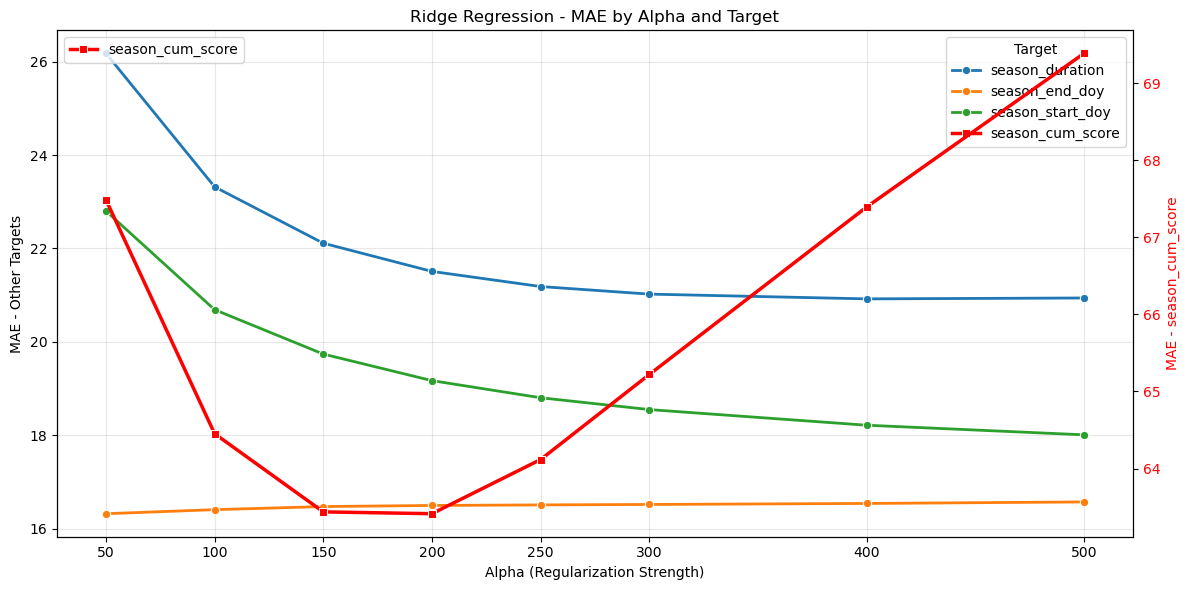

In [15]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Separate season_cum_score from the other targets
df_main = ridge_metrics[
    ridge_metrics["target"] != "season_cum_score"
]

df_season = ridge_metrics[
    ridge_metrics["target"] == "season_cum_score"
]

# Main Y-axis: all other targets
sns.lineplot(
    data=df_main,
    x="alpha",
    y="MAE",
    hue="target",
    marker="o",
    linewidth=2,
    ax=ax1
)

ax1.set_xlabel("Alpha (Regularization Strength)")
ax1.set_ylabel("MAE - Other Targets")
ax1.set_xticks(alphas)
ax1.grid(True, alpha=0.3)

# Secondary Y-axis: season_cum_score
ax2 = ax1.twinx()

sns.lineplot(
    data=df_season,
    x="alpha",
    y="MAE",
    color="red",
    marker="s",
    linewidth=2.5,
    label="season_cum_score",
    ax=ax2
)

ax2.set_ylabel("MAE - season_cum_score", color="red")
ax2.tick_params(axis="y", labelcolor="red")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    title="Target",
    loc="best"
)

ax1.set_title("Ridge Regression - MAE by Alpha and Target")

plt.tight_layout()
plt.show()

Once chosen the alpha (200), I can go on with the ridge regression

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features)
    ]
)

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=200))
])

In [17]:
results_ridge = []

for test_year in [2023, 2024, 2025]:

    train = df[
        (df["year"] < test_year) &
        (df["year"] >= 2021)
    ].copy()

    test = df[df["year"] == test_year].copy()

    for target in targets:

        ridge_model.fit(
            train[numeric_features],
            train[target]
        )

        predictions = ridge_model.predict(
            test[numeric_features]
        )

        for actual, pred, municipality in zip(
            test[target],
            predictions,
            test["municipality"]
        ):

            results_ridge.append({
                "year": test_year,
                "municipality": municipality,
                "target": target,
                "actual": actual,
                "prediction": pred
            })

ridge_results = pd.DataFrame(results_ridge)

In [18]:
ridge_metrics = (
    ridge_results
    .groupby("target")
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["actual"], x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["actual"], x["prediction"]
                )
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(ridge_metrics)

,target,MAE,RMSE
0,season_cum_score,63.414403,77.906103
1,season_duration,21.508134,28.024207
2,season_end_doy,16.494276,20.675712
3,season_start_doy,19.168230,21.564330


Ridge is not improving the baseline (worse MAE, except from season_cum_score)

In [19]:
comparison_metrics = baseline_metrics.pivot(
    index="target",
    columns="model",
    values="MAE"
).merge(ridge_metrics, on="target")
comparison_metrics.drop(columns="RMSE", inplace=True)
comparison_metrics.rename(columns={"MAE" : "ridge"}, inplace=True)
comparison_metrics

,target,pred_last,pred_mean,ridge
0,season_cum_score,61.274242,68.278189,63.414403
1,season_duration,19.679654,17.939683,21.508134
2,season_end_doy,16.683983,16.196970,16.494276
3,season_start_doy,19.714286,15.620635,19.168230


# Model C: Random Forest (including geographic features)

## Intro

Compared to previous models:
* Model A = Historical features, assumes `stationarity`
* Model B = Ridge regression, assumes `Linear correlation`
* Model C = Random Forest, can detect non-linear relations and complex interactions between variables

Machine Learning algorithm based on *Decision Trees*: instead of a single model, several independent decision trees are built, each one making its own prediction. \
The final prediction is obtained from the average of the results of all decision trees (*Ensemble Learning*)

> Decision trees

A *Decision Tree* is a model that takes decisions through sequential questions on the variables. E.g. to predict the temperature of a place:
* Altitudine > 500 m?
* Latitude > 46°?
The data with those features end up in the bucket with predicted temperature = 8°C

Trees progressively divide data in homogeneous groups, for what concerns the target variable. The prediction is generally the mean of the observations in that `leaf` 

> Random Forest

Instead of using a single tree, many trees are built.
The process is:
1. **Bootstrap sampling** = every tree is trained on a casual sample of the dataset (all the dataset, the samples in every tree do not affect sampling of other trees)
2. **Feature randomness** = when building trees, at each subdivision, only a random subset of features is considered 
3. **Tree construction** = every tree autonomously builds its own decision rules
4. **Aggregation** = predictions of trees are combined as average

The prediction of a single tree is the mean of target values of observations in the leaf of the new observation:

$$
T_k(x) = \frac{1}{n_k}\sum_{i \in L_k(x)}y_i
$$

Where:

- $T_k(x)$: prediction of tree $k$.
- $L_k(x)$: observation in the leaf of observation $x$.
- $n_k$: number of observations in the leaf.
- $y_i$: target value for each observation.

The final prediction instead is the average of all predictions obtained from all trees:

$$
\hat{y}(x) = \frac{1}{N}\sum_{k=1}^{N} T_k(x)
$$

Where:

- $\hat{y}(x)$: value predicted from the Random Forest for an observation.
- $N$: number of trees (*n_estimators*).
- $T_k(x)$: value predicted from the decision tree $k$.
- $x$: features involved in the prediction.

The limits of this kind of model are:
* **Overfitting** = if trees are too deep
* **Extrapolation** = not suitable for predictions outside the training set
* **Interpretation** = Harder to interpret the overall behavior of the model
* **Computational cost** = Takes more time and resources

> Main parameters

- `n_estimators`: number of decision trees in the forest.
- `max_depth`: for each tree.
- `min_samples_split`: min observations required to split a node.
- `min_samples_leaf`: min observations required in a leaf.
- `max_features`: number of features considered in each split.


Typical values
- `n_estimators`: 100, 200, 500 Increasing trees does not cause overfitting, but improvements become marginal at some point. 200 is often stable
- `max_depth`: 5, 10, 15, 20, None This parameter needs to be tested carefully
- `min_samples_split`: 2, 5, 10  
- `min_samples_leaf`: 1, 2, 4, 8
- `max_features`: 1, 0.7, 0.5 is the fraction of features. Keeping it low contributes to the generation of different trees

**Side note**: there is no need for Standard Scaler in Random Forest

## Hyperparameter Tuning

A strategy to test different combinations of parameters in Machine Learning algorithms is *Hyperparameter Tuning*:
* Model parameters = automatically set by the model during training
* Hyperparameters = set by the user before training, affecting the way the algorithm learns from the data

The main metrics for evaluation are:
* MAE (Mean Absolute Error): Measures the average absolute difference between actual and predicted values.
* MSE (Mean Squared Error): Measures the average squared prediction error.
* RMSE (Root Mean Squared Error): Measures prediction errors in the same unit as the target variable.
* R² (R-squared): Measures how much of the variance in the target variable is explained by the model.

They can be selected in different ways, every time calculating MAE:
* Grid search = exploring all possible combinations
* Random search = random combinations, computationally more efficient when there are many hyperparameters
* Bayesian Optimization = Defines what combinations to try next, based on the results of previous experiments
    * Initial sampling: Evaluate a few initial hyperparameter configurations.
    * Build a surrogate model: Use the results to build a probabilistic model that estimates the relationship between hyperparameter values and model performance.
    * Acquisition function: Use an acquisition function to identify the next promising configuration to evaluate.
    * Update and repeat: Evaluate the selected configuration, update the surrogate model, and repeat the process until the computational budget is exhausted or a stopping criterion is reached.

## Hyperparameter tuning - pt. 1 (Random search)

The procedure is:
* generate a range from which to pick 20 random parameter combinations
* for every iteration of the random forest algorithm, calculate the MAE
* display the table with all the MAEs
* display the best combination for each target

In [30]:
param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 3, 4, 5, 6, 8, 10, 15, 20],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 11),
    "max_features": uniform(0.5, 0.5), # where the first is the minimum and the second is the amplitude, so between 0.5 and 1 (0.5 + 0.5)
    "bootstrap": [True, False]
}

random_params = list(
    ParameterSampler(
        param_distributions,
        n_iter=20,
        random_state=42
    )
)

In [31]:
random_search_results = []

for iteration, params in enumerate(random_params, start=1):

    results_rf = []

    for test_year in [2023, 2024, 2025]:

        train = df[
            (df["year"] < test_year) &
            (df["year"] >= 2021)
        ].copy()

        test = df[df["year"] == test_year].copy()

        for target in targets:

            rf_model = Pipeline([
                ("preprocessor", preprocessor),
                ("regressor", RandomForestRegressor(
                    **params,
                    random_state=42,
                    n_jobs=-1
                ))
            ])

            rf_model.fit(
                train[numeric_features],
                train[target]
            )

            predictions = rf_model.predict(
                test[numeric_features]
            )

            for actual, pred, municipality in zip(
                test[target],
                predictions,
                test["municipality"]
            ):
                results_rf.append({
                    "iteration": iteration,
                    "year": test_year,
                    "municipality": municipality,
                    "target": target,
                    "actual": actual,
                    "prediction": pred
                })

    # Store predictions
    iteration_results = pd.DataFrame(results_rf)

    # Calculate MAE for each target
    for target in targets:

        target_results = iteration_results[
            iteration_results["target"] == target
        ]

        mae = mean_absolute_error(
            target_results["actual"],
            target_results["prediction"]
        )

        random_search_results.append({
            "iteration": iteration,
            "target": target,
            "MAE": mae,
            **params
        })

In [32]:
rf_random_search_df = pd.DataFrame(random_search_results)

display(
    rf_random_search_df
    .sort_values(["target", "MAE"])
    .reset_index(drop=True)
)

,iteration,target,MAE,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,10,season_cum_score,60.194457,True,5,0.591118,4,3,489
1,6,season_cum_score,61.104589,True,5,0.796207,3,6,406
2,16,season_cum_score,61.733025,True,4,0.853429,3,4,388
3,2,season_cum_score,61.836022,False,4,0.549987,8,6,199
4,17,season_cum_score,61.947562,True,6,0.963150,10,10,127
...,...,...,...,...,...,...,...,...,...
75,9,season_start_doy,16.507919,False,10,0.804998,8,4,305
76,17,season_start_doy,16.508846,True,6,0.963150,10,10,127
77,5,season_start_doy,16.547657,False,20,0.645615,10,4,463
78,3,season_start_doy,16.599893,False,15,0.825444,5,3,443


In [33]:
best_rf_params = (
    rf_random_search_df
    .sort_values("MAE")
    .groupby("target")
    .first()
    .reset_index()
)

display(best_rf_params)

,target,iteration,MAE,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,season_cum_score,10,60.194457,True,5,0.591118,4,3,489
1,season_duration,18,20.153149,True,20,0.811649,2,2,147
2,season_end_doy,1,16.216609,True,5,0.975357,8,6,202
3,season_start_doy,10,15.570822,True,5,0.591118,4,3,489


However, I still have to pick the bets combination **overall**.\
Including *bootstrap*, there are 6 hyperparameters.\
If each one was left with two possible values, there would be $2^6$ = 64 combinations. The selection of the combinations is:
* for each iteration create a table with all the MAEs
* calculate mean and max (however, they are on different scales and their value is not 100% meaningful)
* ranking is maybe a better metric. So I take top 5 iterations by mean rank
* I can choose between the displayed parameters, with the help of 25% and 75% percentiles
* For Bootstrap, I can count the relative fraction of True and False

In [45]:
rf_mae_pivot = rf_random_search_df.pivot(
    index="iteration",
    columns="target",
    values="MAE"
)

display(rf_mae_pivot)

target,season_cum_score,season_duration,season_end_doy,season_start_doy
iteration,,,,
1,61.980832,22.075711,16.216609,16.226578
2,61.836022,21.593333,17.907217,16.021806
3,64.734519,22.766540,17.243237,16.599893
4,62.295964,20.678537,17.995619,15.859542
5,63.763402,22.404778,17.359451,16.547657
6,61.104589,20.349539,17.127619,15.586317
7,62.622158,20.636072,17.376077,15.689435
8,64.822572,23.168462,17.005575,16.211279
9,64.505140,22.359602,17.364011,16.507919


In [46]:
rf_mae_pivot["mean_MAE"] = rf_mae_pivot.mean(axis=1)

rf_mae_pivot["max_MAE"] = rf_mae_pivot[targets].max(axis=1)

display(
    rf_mae_pivot
    .sort_values("mean_MAE")
    .head(10)
)

target,season_cum_score,season_duration,season_end_doy,season_start_doy,mean_MAE,max_MAE
iteration,,,,,,
6,61.104589,20.349539,17.127619,15.586317,28.542016,61.104589
10,60.194457,20.876797,17.539065,15.570822,28.545285,60.194457
16,61.733025,20.984981,16.930413,15.619674,28.817023,61.733025
15,62.122850,21.621005,16.420789,15.998725,29.040842,62.122850
7,62.622158,20.636072,17.376077,15.689435,29.080936,62.622158
1,61.980832,22.075711,16.216609,16.226578,29.124932,61.980832
4,62.295964,20.678537,17.995619,15.859542,29.207416,62.295964
17,61.947562,22.121252,16.256361,16.508846,29.208505,61.947562
19,63.452617,20.826070,16.787250,15.798718,29.216163,63.452617


In [47]:
rf_ranks = rf_mae_pivot[targets].rank(
    axis=0,
    ascending=True
)

rf_ranks["mean_rank"] = rf_ranks.mean(axis=1)

display(
    rf_ranks
    .sort_values("mean_rank")
    .head(10)
)

target,season_start_doy,season_end_doy,season_duration,season_cum_score,mean_rank
iteration,,,,,
6,2.0,10.0,3.0,2.0,4.25
16,3.0,7.0,8.0,3.0,5.25
10,1.0,17.0,7.0,1.0,6.50
19,5.0,5.0,6.0,11.0,6.75
13,6.0,4.0,2.0,17.0,7.25
15,9.0,3.0,11.0,7.0,7.50
18,11.0,6.0,1.0,14.0,8.00
7,4.0,15.0,4.0,9.0,8.00
1,14.0,1.0,12.0,6.0,8.25


In [48]:
top_iterations = (
    rf_ranks
    .sort_values("mean_rank")
    .head(5)
    .index
)

rf_top_params = (
    rf_random_search_df[
        rf_random_search_df["iteration"].isin(top_iterations)
    ]
    .drop_duplicates(subset="iteration")
    .set_index("iteration")
)

display(
    rf_top_params.sort_values("iteration")
)

,target,MAE,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
iteration,,,,,,,,
6,season_start_doy,15.586317,True,5,0.796207,3,6,406
10,season_start_doy,15.570822,True,5,0.591118,4,3,489
13,season_start_doy,15.811833,True,15,0.922267,2,6,379
16,season_start_doy,15.619674,True,4,0.853429,3,4,388
19,season_start_doy,15.798718,True,10,0.834421,5,4,271


In [49]:
numeric_params = [
    "n_estimators",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "max_features"
]

display(
    rf_top_params[numeric_params].describe(
        percentiles=[0.25, 0.50, 0.75]
    ).T
)

,count,mean,std,min,25%,50%,75%,max
n_estimators,5.0,386.600000,77.918547,271.000000,379.000000,388.000000,406.000000,489.000000
max_depth,5.0,7.800000,4.658326,4.000000,5.000000,5.000000,10.000000,15.000000
min_samples_split,5.0,4.600000,1.341641,3.000000,4.000000,4.000000,6.000000,6.000000
min_samples_leaf,5.0,3.400000,1.140175,2.000000,3.000000,3.000000,4.000000,5.000000
max_features,5.0,0.799488,0.125133,0.591118,0.796207,0.834421,0.853429,0.922267


In [50]:
display(
    rf_top_params["bootstrap"].value_counts(normalize=True)
)

bootstrap
True    1.0
Name: proportion, dtype: float64

## Hyperparameter tuning - pt. 2 (Grid search)

In [56]:
param_grid = {
    "n_estimators": [400],
    "max_depth": [5, 10],
    "min_samples_split": [4, 6],
    "min_samples_leaf": [3, 4],
    "max_features": [0.8],
    "bootstrap": [True]
}

grid_params = list(ParameterGrid(param_grid))

In [57]:
grid_search_results = []

for iteration, params in enumerate(grid_params, start=1):

    results_rf = []

    for test_year in [2023, 2024, 2025]:

        train = df[
            (df["year"] < test_year) &
            (df["year"] >= 2021)
        ].copy()

        test = df[df["year"] == test_year].copy()

        for target in targets:

            rf_model = Pipeline([
                ("preprocessor", preprocessor),
                ("regressor", RandomForestRegressor(
                    **params,
                    random_state=42,
                    n_jobs=-1
                ))
            ])

            rf_model.fit(
                train[numeric_features],
                train[target]
            )

            predictions = rf_model.predict(
                test[numeric_features]
            )

            for actual, pred, municipality in zip(
                test[target],
                predictions,
                test["municipality"]
            ):
                results_rf.append({
                    "iteration": iteration,
                    "year": test_year,
                    "municipality": municipality,
                    "target": target,
                    "actual": actual,
                    "prediction": pred
                })

    iteration_results = pd.DataFrame(results_rf)

    for target in targets:

        target_results = iteration_results[
            iteration_results["target"] == target
        ]

        mae = mean_absolute_error(
            target_results["actual"],
            target_results["prediction"]
        )

        grid_search_results.append({
            "iteration": iteration,
            "target": target,
            "MAE": mae,
            **params
        })

In [58]:
rf_grid_search_df = pd.DataFrame(grid_search_results)

display(
    rf_grid_search_df
    .sort_values(["target", "MAE"])
    .reset_index(drop=True)
)

,iteration,target,MAE,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,3,season_cum_score,60.947170,True,5,0.8,4,4,400
1,4,season_cum_score,60.947170,True,5,0.8,4,6,400
2,1,season_cum_score,61.099406,True,5,0.8,3,4,400
3,2,season_cum_score,61.099406,True,5,0.8,3,6,400
4,7,season_cum_score,62.908829,True,10,0.8,4,4,400
5,8,season_cum_score,62.908829,True,10,0.8,4,6,400
6,6,season_cum_score,63.427538,True,10,0.8,3,6,400
7,5,season_cum_score,63.427538,True,10,0.8,3,4,400
8,5,season_duration,20.296353,True,10,0.8,3,4,400
9,6,season_duration,20.296353,True,10,0.8,3,6,400


In [59]:
rf_mae_pivot_grid = rf_grid_search_df.pivot(
    index="iteration",
    columns="target",
    values="MAE"
)

display(rf_mae_pivot_grid)

target,season_cum_score,season_duration,season_end_doy,season_start_doy
iteration,,,,
1,61.099406,20.369398,17.142451,15.554512
2,61.099406,20.369398,17.142451,15.554512
3,60.947170,20.998383,17.035463,15.655054
4,60.947170,20.998383,17.035463,15.655054
5,63.427538,20.296353,17.189727,15.701867
6,63.427538,20.296353,17.189727,15.701867
7,62.908829,20.910143,16.978170,15.661973
8,62.908829,20.910143,16.978170,15.661973


In [60]:
rf_ranks = rf_mae_pivot_grid[targets].rank(
    axis=0,
    ascending=True
)

rf_ranks["mean_rank"] = rf_ranks.mean(axis=1)

display(
    rf_ranks
    .sort_values("mean_rank")
    .head(10)
)

target,season_start_doy,season_end_doy,season_duration,season_cum_score,mean_rank
iteration,,,,,
1,1.0,5.5,3.0,3.5,3.25
2,2.0,5.5,4.0,3.5,3.75
3,4.0,3.5,7.5,1.0,4.00
4,3.0,3.5,7.5,2.0,4.00
8,5.5,1.0,6.0,5.5,4.50
7,5.5,2.0,5.0,5.5,4.50
6,7.5,7.0,1.5,7.0,5.75
5,7.5,8.0,1.5,8.0,6.25


In [61]:
top_iterations = (
    rf_ranks
    .sort_values("mean_rank")
    .head(3)
    .index
)

rf_top_params = (
    rf_grid_search_df[
        rf_grid_search_df["iteration"].isin(top_iterations)
    ]
    .drop_duplicates(subset="iteration")
    .set_index("iteration")
)

display(
    rf_top_params.sort_values("iteration")
)

,target,MAE,bootstrap,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
iteration,,,,,,,,
1,season_start_doy,15.554512,True,5,0.8,3,4,400
2,season_start_doy,15.554512,True,5,0.8,3,6,400
3,season_start_doy,15.655054,True,5,0.8,4,4,400


## Running the chosen parameters

As a first evaluation, all 77 municipalities are considered together

In [62]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        max_depth=5,
        min_samples_leaf=3,
        min_samples_split=4,
        max_features=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1                   # uses all available processors (CPU cores). I could have manually selected 1, 2 etc 
    ))
])

results_rf = []

for test_year in [2023, 2024, 2025]:

    train = df[
        (df["year"] < test_year) &
        (df["year"] >= 2021)
    ].copy()

    test = df[df["year"] == test_year].copy()

    for target in targets:

        rf_model.fit(
            train[numeric_features],
            train[target]
        )

        predictions = rf_model.predict(
            test[numeric_features]
        )

        for actual, pred, municipality in zip(
            test[target],
            predictions,
            test["municipality"]
        ):
            results_rf.append({
                "year": test_year,
                "municipality": municipality,
                "target": target,
                "actual": actual,
                "prediction": pred
            })

rf_results = pd.DataFrame(results_rf)


In [63]:
rf_metrics = (
    rf_results
    .groupby("target")
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["actual"], x["prediction"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["actual"], x["prediction"]
                )
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(rf_metrics)


,target,MAE,RMSE
0,season_cum_score,61.099406,76.744281
1,season_duration,20.369398,25.092292
2,season_end_doy,17.142451,23.289175
3,season_start_doy,15.554512,20.710942


In [68]:
comparison_metrics = comparison_metrics.merge(rf_metrics, on="target")
comparison_metrics.drop(columns="RMSE", inplace=True)
comparison_metrics.rename(columns={"MAE" : "RF"}, inplace=True)

In [69]:
comparison_metrics

,target,pred_last,pred_mean,ridge,RF
0,season_cum_score,61.274242,68.278189,63.414403,61.099406
1,season_duration,19.679654,17.939683,21.508134,20.369398
2,season_end_doy,16.683983,16.196970,16.494276,17.142451
3,season_start_doy,19.714286,15.620635,19.168230,15.554512


Random forest is similar to the baseline pred_mean (better MAE for season_cum_score and for season_start_doy)

# Summing up

Model selection based on validation performance:
* `Lag 1 (pred_last)`: not best in anything
* `Expanding Mean (pred_mean)`: best in season duration (even if it is correlated to start and end) and season_end_doy
* `Ridge`: not best in anything
* `Random Forest`: best in season_cum_score and season_start_doy

| Target           | Model  |
|------            |----    |
| season_cum_score | RF     |
| season_duration  | EM     |
| season_end_doy   | EM     |
| season_start_doy | RF     |